In [1]:
from pathlib import Path
import cv2 
import numpy as np
import matplotlib.pyplot as plt

In [2]:

def load_image(url: str = "..\\notebooks\\test_images\\lenna_(test_image).png"):
    """
    This function is simply for loading an image
    """
    image_path = Path(url).resolve()
    
    print(f"Looking for video at: {image_path}")
    
    if not image_path.is_file():
        raise FileNotFoundError(f"Video not found: {image_path}")

    image = cv2.imread(str(image_path))
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

img = load_image()

Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\notebooks\test_images\Lenna_(test_image).png


### **CLAHE FUNCTIONS**

In [12]:
def choose_clahe_grid(frame, tile_size=64):
    """
    Automatically chooses a grid based on the image resolution.

    Each CLAHE tile should cover approximately 64 x 64 pixels.

    The grid dimensions are restricted to odd numbers
    between 5 and 15, making them compatible with
    Gaussian blur kernel requirements.
    """
    h, w = frame.shape[:2]

    grid_x = int(np.clip(round(w / tile_size), 5, 15))
    grid_y = int(np.clip(round(h / tile_size), 5, 15))

    # Ensure both dimensions are odd
    if grid_x % 2 == 0:
        grid_x += 1

    if grid_y % 2 == 0:
        grid_y += 1

    return (grid_x, grid_y)

def choose_clahe_limit(gray):
    """
    Estimate image contrast using the 20th and 80th
    percentiles and adapt the CLAHE clip limit.

    Lower contrast -> higher clip limit
    Higher contrast -> lower clip limit
    """

    p20, p80 = np.percentile(gray, [20, 80])
    contrast = p80 - p20

    clip_limit = np.interp(
        contrast,
        [0, 150],
        [3.0, 1.5]
    )

    return float(clip_limit)

## **Gaussian Blur**

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

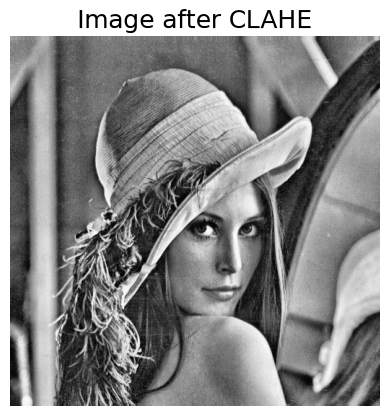

In [44]:
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

clip_limit = choose_clahe_limit(img_gray)
grid_size = choose_clahe_grid(img_gray)

clahe = cv2.createCLAHE(
    clipLimit=clip_limit,
    tileGridSize=grid_size
)

img_clahe = clahe.apply(img_gray)
plt.imshow(img_clahe, cmap = "gray")
plt.title("Image after CLAHE", fontsize = 18)
plt.axis("off")

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

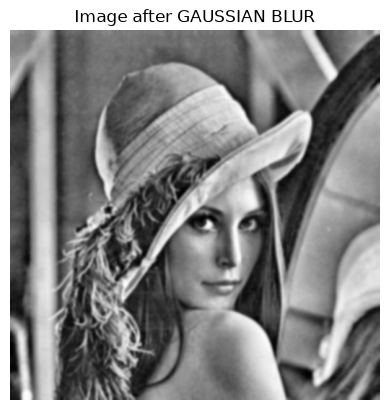

In [53]:
img_gaus = cv2.GaussianBlur(img_clahe, (0,0) , 1.5)

plt.imshow(img_gaus, cmap = "gray")
plt.title("Image after GAUSSIAN BLUR", fontsize = 12)
plt.axis("off")


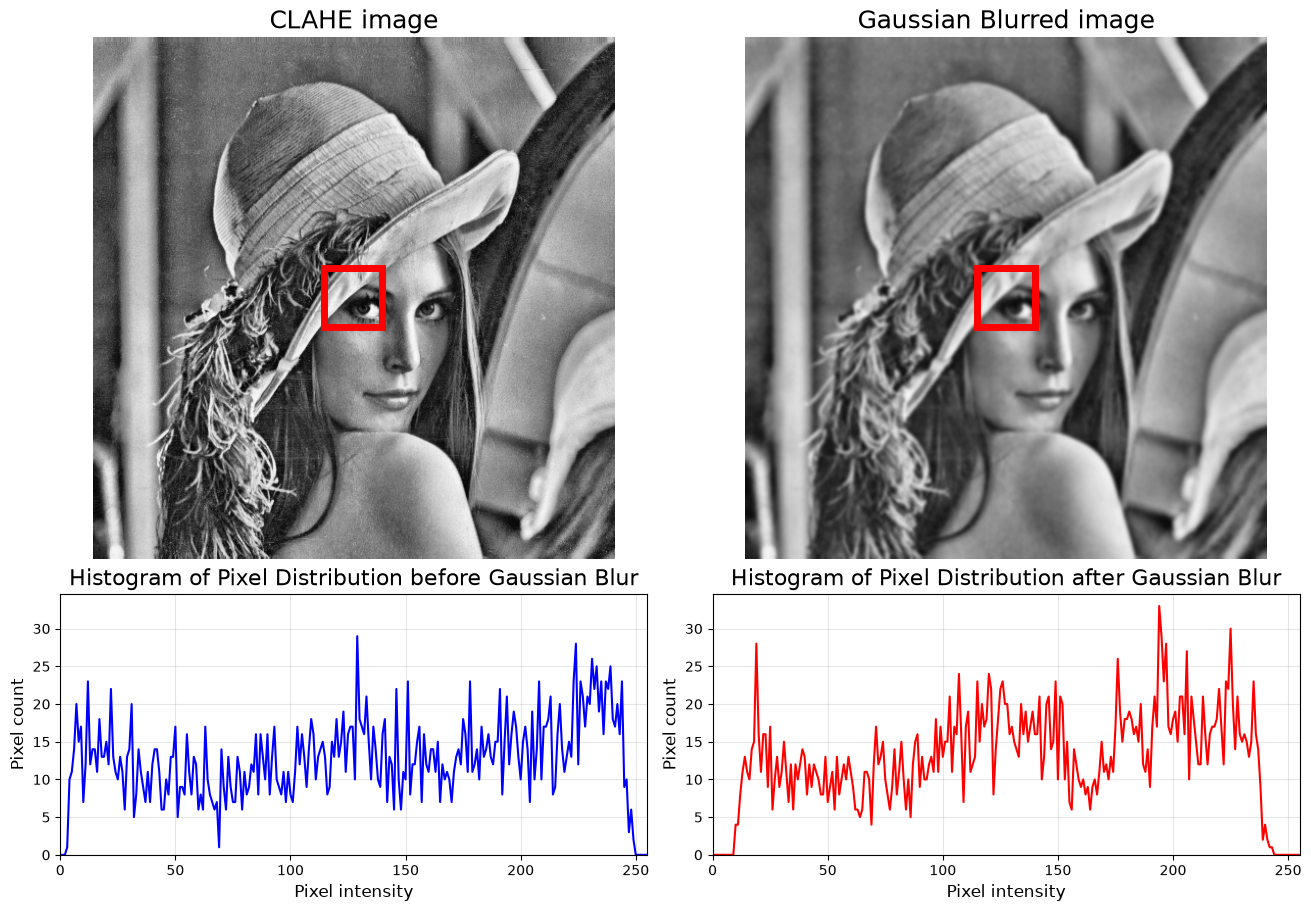

In [54]:
from matplotlib.patches import Rectangle

# Calculate grid boundaries
h, w = img_gaus.shape
nx, ny = grid_size

x_edges = np.linspace(0, w, nx + 1, dtype=int)
y_edges = np.linspace(0, h, ny + 1, dtype=int)

# Select the center grid area
col = nx // 2
row = ny // 2

x0, x1 = x_edges[col], x_edges[col + 1]
y0, y1 = y_edges[row], y_edges[row + 1]

# Extract the same area before and after
tile_before = img_clahe[y0:y1, x0:x1]
tile_after = img_gaus[y0:y1, x0:x1]

# Calculate histograms
hist_before = cv2.calcHist([tile_before], [0], None, [256], [0, 256])
hist_after = cv2.calcHist([tile_after], [0], None, [256], [0, 256])

fig, axs = plt.subplots(
    2, 2,
    figsize=(13, 9),
    gridspec_kw={"height_ratios": [3, 1.5]},
    layout="constrained"
)

for ax, image, title in zip(
    axs[0],
    [img_clahe, img_gaus],
    ["CLAHE image", "Gaussian Blurred image"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    # for x in x_edges[1:-1]:
    #     ax.axvline(x - 0.5, color="yellow", linewidth=0.8)

    # for y in y_edges[1:-1]:
    #     ax.axhline(y - 0.5, color="yellow", linewidth=0.8)

    rect = Rectangle(
        (x0 - 0.5, y0 - 0.5),
        x1 - x0,
        y1 - y0,
        edgecolor="red",
        facecolor="none",
        linewidth=5
    )
    ax.add_patch(rect)

    ax.set_title(title, fontsize = 18)
    ax.axis("off")

axs[1, 0].plot(hist_before, color="blue")
axs[1, 0].set_title("Histogram of Pixel Distribution before Gaussian Blur", fontsize = 16)

axs[1, 1].plot(hist_after, color="red")
axs[1, 1].set_title("Histogram of Pixel Distribution after Gaussian Blur", fontsize = 16)

for ax in axs[1]:
    ax.set_xlim(0, 255)
    ax.set_xlabel("Pixel intensity", fontsize = 12)
    ax.set_ylabel("Pixel count", fontsize = 12)
    ax.grid(alpha=0.3)

max_count = max(hist_before.max(), hist_after.max())
for ax in axs[1]:
    ax.set_ylim(0, max_count * 1.05)

# plt.suptitle(
#     f"CLAHE: Clip Limit = {round(clip_limit,2)}, Grid Size = {grid_size}",
#     fontsize=15
# )

plt.show()

# **Test on video**

In [55]:
import cv2
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def get_training_video(url: str = r"..\data\videos\black_background_noHuman.mp4"):
    """
    Loads a training video from a file location.

    Args:
        url: File location

    Returns:
        cv2.VideoCapture object
    """

    video_path = Path(url).resolve()

    print(f"Looking for video at: {video_path}")

    if not video_path.is_file():
        raise FileNotFoundError(f"Video not found: {video_path}")

    video = cv2.VideoCapture(str(video_path))

    if not video.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    fps = video.get(cv2.CAP_PROP_FPS)
    total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

    print(f"FPS: {fps}")
    print(f"Total frames: {total_frames}")
    print(f"Total video length: {round(total_frames/fps,2)} seconds")

    return video

In [ ]:
import cv2
import numpy as np

video_path1 = r"..\data\videos\black_background_yesHuman.mp4"
video_path2 = r"..\data\videos\white_background_yesHuman.mp4"
video_path3 = r"..\data\videos\wood_background_yesHuman.mp4"

videos = [
    get_training_video(video_path1),
    get_training_video(video_path2),
    get_training_video(video_path3)
]


try:
    while True:
        frames = []
        for i, video in enumerate(videos):
            ret, frame = video.read()

            if not ret:
                break

            img_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            # Perform CLAHE
            clip_limit = choose_clahe_limit(img_gray)
            grid_size = choose_clahe_grid(img_gray)

            clahe = cv2.createCLAHE(
                clipLimit=clip_limit,
                tileGridSize=grid_size
            )
            img_clahe = clahe.apply(img_gray)
            # Gaussian Blur
            frame = cv2.GaussianBlur(img_clahe, (0,0) , 1.5)

            processed = cv2.resize(frame, (480, 270))
            frames.append(processed)

        if len(frames) != len(videos):
            break

        for i, frame in enumerate(frames):
            name = f"Video {i+1}"
            cv2.imshow(name, frame)
            cv2.moveWindow(name, i * 500, 100)

        if cv2.waitKey(33) & 0xFF == ord('q'):
            break

finally:
    for video in videos:
        video.release()

    cv2.destroyAllWindows()

Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\black_background_yesHuman.mp4
FPS: 29.974798258788788
Total frames: 471.0
Total video length: 15.71 seconds
Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\white_background_yesHuman.mp4
FPS: 29.97700915823034
Total frames: 472.0
Total video length: 15.75 seconds
Looking for video at: C:\Users\Matti\Desktop\Master Courses DTU\Image_Analysis_Micro\DARTS-Dartboard-Automatic-Recognition-Tracking-System\data\videos\wood_background_yesHuman.mp4
FPS: 29.985681983553842
Total frames: 511.0
Total video length: 17.04 seconds
